# Step 9: Ablations

Which components the results depend on, and whether they can be trusted. Code: `experiments/13_ablations/` and the A7 variants in `experiments/12_scratch_nn/nn_scratch.py`. Details: `docs/steps/09_ablations.md`.

In [1]:
# Imports and paths
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import nbutils as U
A = U.EXP / "13_ablations/results"
pd.set_option("display.width", 200)

## A9 Author overlap
87% of test rows come from authors seen in training. If models memorised authors, AUC would drop on the unseen-author rows.

In [2]:
# Seen vs unseen authors
info = U.read_json(A / "a9_author_overlap.json")
print(f"unseen-author rows: {info['unseen_author_rows']:,} of {info['test_rows']:,} ({info['unseen_share']:.1%})")
b = info["stack_vs_baseline_on_unseen"]
print(f"compliant stack vs baseline on unseen authors: {b['diff']:+.4f} [{b['ci_low']:+.4f}, {b['ci_high']:+.4f}]")
U.show(pd.read_csv(A / "a9_author_overlap.csv"))

unseen-author rows: 18,014 of 137,065 (13.1%)
compliant stack vs baseline on unseen authors: +0.0320 [+0.0287, +0.0357]


,model,auc_all,auc_seen_authors,auc_unseen_authors,drop_unseen_vs_seen
0,lgbm_reply_tfidf_surface,0.8074,0.8071,0.8108,0.0037
1,lgbm_lrscore_cues_contrast,0.8296,0.8296,0.8307,0.0011
2,lr_word_char_surface,0.8184,0.8184,0.8197,0.0013
3,ebm_full,0.8229,0.8230,0.8234,0.0004
4,scratch_pair,0.8242,0.8243,0.8249,0.0006
5,compliant LR stack,0.8416,0.8416,0.8428,0.0012
6,roberta_pair_conv (reference),0.8809,0.8804,0.8849,0.0046


## A4 Stacking members
LR stack over calibrated logits with one model family removed, or with that family alone.

In [3]:
# Drop one family at a time
a4 = pd.read_csv(A / "a4_stacking_members.csv")
U.show(a4[["set", "variant", "n_members", "val_auc_oof", "test_auc", "d_auc_vs_full", "ci_low", "ci_high"]])

,set,variant,n_members,val_auc_oof,test_auc,d_auc_vs_full,ci_low,ci_high
0,sarc_random,all compliant members,24,0.8374,0.8416,NaN,NaN,NaN
1,sarc_random,without GBDT baseline,20,0.8372,0.8415,-0.0001,-0.0002,-0.0000
2,sarc_random,only GBDT baseline,4,0.8062,0.8090,-0.0326,-0.0337,-0.0314
3,sarc_random,without GBDT improved,16,0.8346,0.8388,-0.0028,-0.0032,-0.0025
4,sarc_random,only GBDT improved,8,0.8275,0.8314,-0.0101,-0.0109,-0.0095
5,sarc_random,without Linear,19,0.8370,0.8410,-0.0006,-0.0007,-0.0005
6,sarc_random,only Linear,5,0.8185,0.8226,-0.0190,-0.0200,-0.0181
7,sarc_random,without Naive Bayes,22,0.8367,0.8409,-0.0007,-0.0009,-0.0005
8,sarc_random,only Naive Bayes,2,0.7863,0.7892,-0.0524,-0.0541,-0.0508
9,sarc_random,without Glass-box,21,0.8369,0.8411,-0.0005,-0.0006,-0.0003


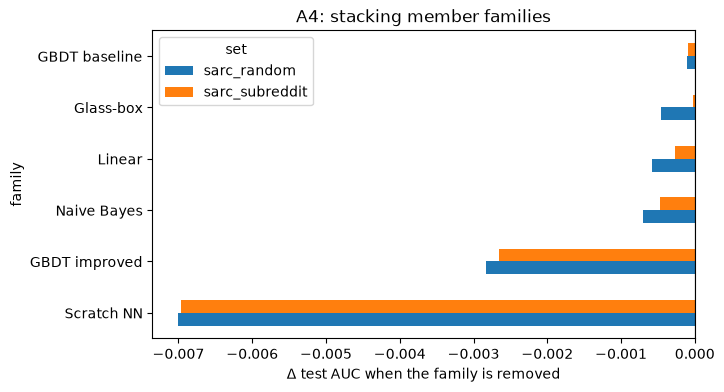

In [4]:
# Loss from removing each family
w = a4[a4.variant.str.startswith("without")].assign(family=lambda d: d.variant.str.replace("without ", ""))
p = w.pivot(index="family", columns="set", values="d_auc_vs_full").sort_values("sarc_random")
fig, ax = plt.subplots(figsize=(7, 4)); p.plot.barh(ax=ax)
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("Δ test AUC when the family is removed")
ax.set_title("A4: stacking member families"); U.savefig(fig, "S09_a4_members.png"); plt.show()

## A5 Stacking design

In [5]:
# Design variants on sarc_random
U.show(pd.read_csv(A / "a5_stacking_design.csv"))

,set,variant,val_auc_oof,test_auc,d_auc_vs_full,ci_low,ci_high,meta_rounds
0,sarc_random,"reference: calibrated logits, LR, cross-fitted",0.8374,0.8416,NaN,NaN,NaN,NaN
1,sarc_random,no calibration,0.8374,0.8416,-0.0000,-0.0000,0.0000,NaN
2,sarc_random,probability inputs instead of logits,0.8370,0.8411,-0.0005,-0.0006,-0.0003,NaN
3,sarc_random,"LightGBM meta-learner, no meta-features",0.8371,0.8414,-0.0002,-0.0004,0.0000,471.0
4,sarc_random,LightGBM meta-learner + meta-features,0.8373,0.8417,0.0001,-0.0002,0.0003,598.0
5,sarc_random,no cross-fitting (in-sample val AUC),0.8375,0.8416,0.0000,NaN,NaN,NaN


## A2 Text representation
The word + char LR from step 3 with one block removed at a time.

In [6]:
# Word, char and surface blocks
a2 = U.read_json(A / "a2_text_representation.json")
rows = [{"variant": k, "blocks": " + ".join(v["blocks"]), "features": v["n_features"], "val_auc": v["val_auc"],
         "test_auc": v["test"]["roc_auc"], "p75_recall": v["test"].get("p75_recall"),
         "d_vs_full": v.get("vs_full", {}).get("diff"), "ci_low": v.get("vs_full", {}).get("ci_low"),
         "ci_high": v.get("vs_full", {}).get("ci_high")} for k, v in a2.items()]
U.show(pd.DataFrame(rows))

,variant,blocks,features,val_auc,test_auc,p75_recall,d_vs_full,ci_low,ci_high
0,lr_word_surface,word + surface,299309,0.7984,0.8008,0.6897,-0.0176,-0.0187,-0.0167
1,lr_char_surface,char + surface,240271,0.7932,0.7981,0.6799,-0.0204,-0.0213,-0.0193
2,lr_word_char,word + char,539546,0.8121,0.8166,0.7248,-0.0018,-0.0021,-0.0015
3,lr_word_char_surface,word + char + surface,539563,0.8142,0.8184,0.7290,NaN,NaN,NaN


## A1 Feature blocks
The best compliant LightGBM retrained with one feature block removed.

In [7]:
# Leave one block out
a1 = U.read_json(A / "a1_feature_blocks.json")
rows = []
for k, v in a1.items():
    for s in ["sarc_random", "sarc_subreddit"]:
        r = v[s]; b = r.get("vs_full", {})
        rows.append({"variant": k, "set": s, "features": r["n_features"], "trees": r["n_trees"], "test_auc": r["test"]["roc_auc"],
                     "p75_recall": r["test"].get("p75_recall"), "d_vs_full": b.get("diff"), "ci_low": b.get("ci_low"), "ci_high": b.get("ci_high")})
a1t = pd.DataFrame(rows); U.show(a1t)

,variant,set,features,trees,test_auc,p75_recall,d_vs_full,ci_low,ci_high
0,full,sarc_random,20061,496,0.8296,0.7512,NaN,NaN,NaN
1,full,sarc_subreddit,20061,496,0.8226,0.7479,NaN,NaN,NaN
2,no_tfidf,sarc_random,61,145,0.8240,0.7392,-0.0056,-0.0062,-0.0050
3,no_tfidf,sarc_subreddit,61,145,0.8159,0.7333,-0.0067,-0.0072,-0.0061
4,no_surface,sarc_random,20044,518,0.8286,0.7486,-0.0011,-0.0015,-0.0006
5,no_surface,sarc_subreddit,20044,518,0.8208,0.7437,-0.0019,-0.0023,-0.0014
6,no_cues,sarc_random,20036,439,0.8286,0.7497,-0.0011,-0.0015,-0.0007
7,no_cues,sarc_subreddit,20036,439,0.8210,0.7429,-0.0016,-0.0021,-0.0012
8,no_contrast,sarc_random,20043,548,0.8276,0.7462,-0.0020,-0.0024,-0.0015
9,no_contrast,sarc_subreddit,20043,548,0.8205,0.7412,-0.0021,-0.0027,-0.0016


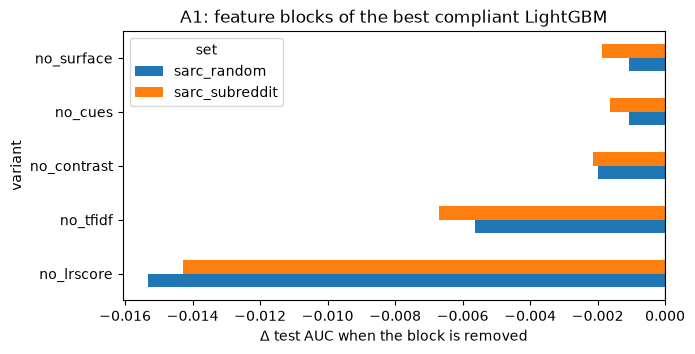

In [8]:
# Loss from removing each block
p = a1t[a1t.variant != "full"].pivot(index="variant", columns="set", values="d_vs_full").sort_values("sarc_random")
fig, ax = plt.subplots(figsize=(7, 3.5)); p.plot.barh(ax=ax); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Δ test AUC when the block is removed"); ax.set_title("A1: feature blocks of the best compliant LightGBM")
U.savefig(fig, "S09_a1_blocks.png"); plt.show()

## A6 EBM design

In [9]:
# Interactions and training-set size
a6 = U.read_json(A / "a6_ebm_design.json")
ref = pd.DataFrame([{"variant": "full EBM (step 4)", "train_rows": 639638, "n_terms": 81, "test_auc": 0.8229},
                    {"variant": "no text score (step 4)", "train_rows": 639638, "n_terms": 80, "test_auc": 0.7123}])
U.show(pd.concat([ref, pd.DataFrame([{"variant": k, "train_rows": v["train_rows"], "n_terms": v["n_terms"], "test_auc": v["test"]["roc_auc"],
                                      "fit_seconds": v["fit_seconds"]} for k, v in a6.items()])]))

,variant,train_rows,n_terms,test_auc,fit_seconds
0,full EBM (step 4),639638,81,0.8229,NaN
1,no text score (step 4),639638,80,0.7123,NaN
0,ebm_no_interactions,639638,66,0.8215,156.0
1,ebm_sample200k,200000,81,0.8225,27.0


## A7 Network design
ESIM without cross-attention, and a same-size Transformer trained from scratch.

In [10]:
# Test AUC and paired differences
a7 = U.read_json(A / "a7_network_design.json")
display(pd.Series(a7["test_auc"]).round(4))
U.show(pd.DataFrame({k: v for k, v in a7.items() if "_vs_" in k}).T[["diff", "ci_low", "ci_high"]])

scratch_reply               0.8180
scratch_pair_noattn         0.8232
scratch_pair                0.8242
scratch_transformer_pair    0.8052
roberta_pair_conv           0.8809
dtype: float64

,diff,ci_low,ci_high
scratch_pair_vs_scratch_pair_noattn,0.0010,-0.0001,0.0020
scratch_pair_noattn_vs_scratch_reply,0.0052,0.0042,0.0062
scratch_pair_vs_scratch_reply,0.0063,0.0051,0.0075
scratch_pair_vs_scratch_transformer_pair,0.0190,0.0177,0.0204
roberta_pair_conv_vs_scratch_transformer_pair,0.0756,0.0738,0.0774
roberta_pair_conv_vs_scratch_pair,0.0566,0.0551,0.0583


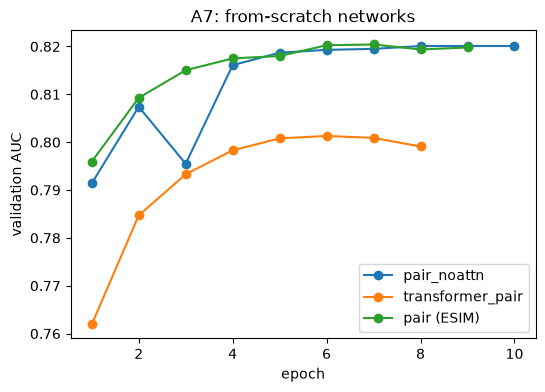

In [11]:
# Validation curves
fig, ax = plt.subplots(figsize=(6, 4))
for k in ["pair_noattn", "transformer_pair"]:
    e = np.array(a7[k]["evals"]); ax.plot(e[:, 0], e[:, 1], marker="o", label=k)
e = pd.DataFrame(U.read_json(U.EXP / "12_scratch_nn/results/scratch_pair__sarc_random.json")["evals"])
ax.plot(e["epoch"], e["val_auc"], marker="o", label="pair (ESIM)")
ax.set_xlabel("epoch"); ax.set_ylabel("validation AUC"); ax.legend(); ax.set_title("A7: from-scratch networks")
U.savefig(fig, "S09_a7_curves.png"); plt.show()

## A8 Trailing punctuation
Word + char LR (no surface counts) with trailing punctuation stripped from every reply.

In [12]:
# Endings by class and AUC after stripping
a8 = U.read_json(A / "a8_punctuation_artifact.json")
display(pd.DataFrame(a8["endings_train"]).round(3))
print(f"test replies changed by stripping: {a8['share_changed_by_strip']:.1%}")
U.show(pd.DataFrame([{"variant": k, "test_auc": v["test"]["roc_auc"], **{f"d_{a}": b for a, b in v.get("vs_reference", {}).items() if a != "p_le_0"}}
                     for k, v in a8.items() if k.startswith("train_")]))

,not sarcastic,sarcastic
exclamation,0.046,0.135
full stop,0.527,0.407
letter or digit,0.262,0.326
other,0.041,0.021
question,0.124,0.111


test replies changed by stripping: 67.4%


,variant,test_auc,d_diff,d_ci_low,d_ci_high
0,train_original__test_original,0.8166,NaN,NaN,NaN
1,train_original__test_stripped,0.8045,-0.0122,-0.0130,-0.0114
2,train_stripped__test_stripped,0.8069,-0.0097,-0.0106,-0.0090


## Takeaways

- **A9:** no model loses AUC on authors never seen in training, so the results are not driven by author memorisation.
- **A4:** the from-scratch networks are the only family whose removal costs more than 0.003; improved GBDTs cost 0.003; every other family is below 0.001. Losses are the same on `sarc_subreddit`.
- **A5:** calibration, input scale, meta-learner type, meta-features and cross-fitting all change test AUC by at most 0.0005: the stack is robust to its design.
- **A2:** word and character n-grams are complementary: each alone gives about 0.80, together 0.8166; surface features add a further +0.0018.
- **A1:** the LR text score is the block the best LightGBM depends on (−0.015); TF-IDF −0.006; contrast, cues and surface −0.001 to −0.002 each.
- **A6:** interactions add +0.0014; a 200k sample loses only 0.0004 once the text score is a feature.
- **A7:** cross-attention adds only +0.0010 over encoding the parent separately; a same-size Transformer from scratch is 0.019 below the ESIM, so RoBERTa's lead comes from pretraining, not from the Transformer architecture.
- **A8:** about 0.01 AUC depends on how replies end; with endings removed the LR still reaches 0.807.